# Прогноз первой попытки и оценка освоения навыков

На синтетическом наборе Finny рассматриваются две задачи. Первая — оценить вероятность верного ответа до того, как ребёнок ответил на задание. Вторая — сопоставить дневное состояние BKT со скрытой способностью виртуального ребёнка. Единица наблюдения и целевая величина у этих задач различаются.

## Данные и проверка целостности

Таблицы и интервалы взяты из сохранённых экспериментов v1–v5. Сначала проверяется соответствие каждого артефакта локальному журналу `sim_v3/events.csv`. При отсутствии контрольной суммы строка получает отметку «не проверено». Расхождение с записанной суммой прерывает выполнение.

In [1]:
import hashlib
import json
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ml = next(p for parent in (Path.cwd(), *Path.cwd().parents)
          for p in (parent, parent / "ml") if (p / "results/knowledge_models_v1.json").is_file())
results = ml / "results"
events_path = ml / "data/sim_v3/events.csv"
suffixes = ["v1", "v2_bounds", "v3_ci", "v4_plearn", "v5_mastery_eval"]
names = [f"knowledge_models_{suffix}.json" for suffix in suffixes]
artifacts = {name: json.loads((results / name).read_text(encoding="utf-8")) for name in names}
v1, v2, v3, v4, v5 = (artifacts[name] for name in names)


def check_hashes(files: dict, actual: str) -> None:
    rows = []
    conflicts = []
    for name, artifact in files.items():
        present = "events_sha256" in artifact
        match = "не проверено"
        if present:
            match = "да" if artifact["events_sha256"] == actual else "нет"
            if match == "нет":
                conflicts.append(name)
        rows.append({"Артефакт": name, "Есть events_sha256": "да" if present else "нет", "Совпал": match})
    print("events_sha256 =", actual)
    display(pd.DataFrame(rows).set_index("Артефакт"))
    if conflicts:
        raise ValueError("Контрольная сумма расходится с журналом в " + ", ".join(conflicts))


check_hashes(artifacts, hashlib.sha256(events_path.read_bytes()).hexdigest())

events_sha256 = d5de0d2df5baf7ac088818e29dd338c1408ec22cc4d02d414e12c814c7bf7b3c


,Есть events_sha256,Совпал
Артефакт,,
knowledge_models_v1.json,да,да
knowledge_models_v2_bounds.json,да,да
knowledge_models_v3_ci.json,да,да
knowledge_models_v4_plearn.json,да,да
knowledge_models_v5_mastery_eval.json,да,да


## Выборка и порядок прогноза

Берётся первая попытка задания в сессии. Первые ответы одного ребёнка по одному навыку с общей сессией и временем образуют шаг. Прогноз строится по истории до шага. Затем все верные и ошибочные ответы группы пополняют историю. В метриках каждый первый ответ имеет одинаковый вес.

Разбиение выполнено по детям. Для выбора границ внутри исходной обучающей группы выделена валидационная подвыборка. После выбора параметров границ модель повторно обучена на всей обучающей группе.

In [2]:
meta = v1["dataset"]
print(f"sim_v3: {meta['children']} детей, {meta['weeks']} недель, seed {meta['seed']}.")
print(f"В журнале {meta['rows_events']} ответов всех попыток, из них "
      f"{v3['train_answers'] + v3['test_answers']} первых.")
groups = v4["children"]
display(pd.DataFrame([
    ["Обучение v1 / итоговое обучение v4", v3["train_children"], v3["train_answers"]],
    ["Из них для подбора на обучении", len(groups["train"]), v4["train_answers"]],
    ["Из них для валидации", len(groups["validation"]), v4["validation_grid"][0]["metrics"]["answers"]],
    ["Отложенный тест", v3["test_children"], v3["test_answers"]],
], columns=["Выборка", "Дети", "Первые ответы"]).set_index("Выборка"))

sim_v3: 300 детей, 8 недель, seed 42.
В журнале 104452 ответов всех попыток, из них 50045 первых.


,Дети,Первые ответы
Выборка,,
Обучение v1 / итоговое обучение v4,240,40226
Из них для подбора на обучении,192,31715
Из них для валидации,48,8511
Отложенный тест,60,9819


## Пять прогнозов верного ответа

Для навыка $k$ обозначим через $S$ и $F$ числа предыдущих верных и ошибочных первых ответов ребёнка. Коэффициенты оцениваются на обучающих детях отдельно для каждого навыка. $\sigma(z)=1/(1+e^{-z})$.

| Модель | Прогноз перед очередным ответом |
|---|---|
| Доля по навыку | $r_k=C_k/N_k$, где $C_k$ из $N_k$ обучающих ответов верны. |
| Личная доля | $(S+5r_k)/(S+F+5)$. Пять условных наблюдений сглаживают оценку к $r_k$ при короткой истории. |
| PFA | $\sigma(\beta_{0k}+\beta_{Sk}S+\beta_{Fk}F)$. |
| PFA с заданием, диагностическая | К линейной части PFA добавляется коэффициент задания $\gamma_{kj}$. У опорного и ранее не встречавшегося задания этот вклад нулевой. При одном задании прогноз совпадает с PFA. Для обеих регрессий применяется L2-регуляризация, $C=1$. |
| BKT | При $L=P(\text{освоено до шага})$ прогноз верного ответа равен $L(1-s)+(1-L)g$, где $s=p_{\rm slip}$ и $g=p_{\rm guess}$. |

BKT начинает с $L=p_{\rm init}$. Для группы из $c$ верных и $w$ ошибочных ответов веса двух состояний равны $a=L(1-s)^c s^w$ и $b=(1-L)g^c(1-g)^w$. Байесовская оценка после наблюдения равна $q=a/(a+b)$. Один переход обучения на всю группу даёт $L_{\rm next}=q+(1-q)p_{\rm learn}$. В этой модели отсутствует забывание.

В сравнении пяти моделей (v3) BKT использует исходные интервалы: для $p_{\rm init}$ и $p_{\rm learn}$ — $[0{,}001;0{,}999]$, для $g$ и $s$ — $[0{,}001;0{,}499]$. Изменение потолка $p_{\rm learn}$ рассматривается отдельно в эксперименте v4.

## 4.1b. Сравнение моделей на отложенных детях

AUC измеряет способность ранжировать верные ответы выше ошибочных. RMSE измеряет среднеквадратичную ошибку вероятности относительно наблюдаемого исхода 0 или 1. Более высокий AUC и меньший RMSE соответствуют лучшему прогнозу по выбранной метрике.

В квадратных скобках указаны 95%-ные процентильные интервалы. В каждом из 2 000 повторов (seed 2026) с возвращением выбирались 60 детей со всей историей. Все модели оценивались на одних и тех же выборках. Интервалы отражают разброс по тестовым детям при фиксированных обученных моделях.

In [3]:
labels = {"rate": "Доля по навыку", "personal": "Личная доля", "PFA": "PFA",
          "task_diagnostic": "PFA с заданием (диагн.)", "BKT": "BKT"}


def with_ci(value: float, bounds: list, digits: int = 4) -> str:
    low, high = bounds
    return f"{value:.{digits}f} [{low:.{digits}f}, {high:.{digits}f}]"


def metrics_ci(row: dict) -> dict:
    return {m: with_ci(row[m]["estimate"], row[m]["ci95"]) for m in ("AUC", "RMSE")}


display(pd.DataFrame([{"Модель": title, **metrics_ci(v3["metrics"][key])}
                      for key, title in labels.items()]).set_index("Модель"))

,AUC,RMSE
Модель,,
Доля по навыку,"0.6105 [0.5942, 0.6274]","0.4653 [0.4546, 0.4758]"
Личная доля,"0.6423 [0.6163, 0.6644]","0.4620 [0.4500, 0.4731]"
PFA,"0.6694 [0.6492, 0.6886]","0.4548 [0.4437, 0.4655]"
PFA с заданием (диагн.),"0.6958 [0.6781, 0.7128]","0.4480 [0.4367, 0.4579]"
BKT,"0.6696 [0.6485, 0.6890]","0.4549 [0.4436, 0.4656]"


### Попарные разности

Каждая строка показывает A − B. Для A положительная разность AUC и отрицательная разность RMSE означают преимущество по соответствующей метрике. У BKT и PFA интервалы обеих разностей включают ноль.

In [4]:
display(pd.DataFrame([{"A": labels[row["A"]], "B": labels[row["B"]], **metrics_ci(row)}
                      for row in v3["differences"]]).set_index(["A", "B"]))

,,AUC,RMSE
A,B,,
PFA,Доля по навыку,"0.0589 [0.0444, 0.0713]","-0.0105 [-0.0133, -0.0079]"
BKT,Доля по навыку,"0.0591 [0.0430, 0.0736]","-0.0104 [-0.0138, -0.0072]"
Личная доля,Доля по навыку,"0.0318 [0.0118, 0.0491]","-0.0033 [-0.0070, 0.0000]"
PFA с заданием (диагн.),Доля по навыку,"0.0853 [0.0720, 0.0973]","-0.0174 [-0.0209, -0.0140]"
BKT,PFA,"0.0002 [-0.0044, 0.0051]","0.0001 [-0.0012, 0.0014]"
Личная доля,PFA,"-0.0271 [-0.0381, -0.0163]","0.0072 [0.0050, 0.0094]"
PFA с заданием (диагн.),PFA,"0.0263 [0.0201, 0.0330]","-0.0068 [-0.0085, -0.0052]"
Личная доля,BKT,"-0.0273 [-0.0401, -0.0152]","0.0071 [0.0044, 0.0098]"
PFA с заданием (диагн.),BKT,"0.0262 [0.0179, 0.0349]","-0.0070 [-0.0090, -0.0050]"


### ROC-кривые исходных трёх моделей

Артефакт v1 содержит обученные коэффициенты трёх моделей. Для рисунка они применяются к наблюдаемым полям тестового журнала. Каждый шаг вносит в ROC число верных и ошибочных первых ответов. Площади под построенными кривыми сверяются с v1. Сводная таблица выше охватывает все пять моделей.

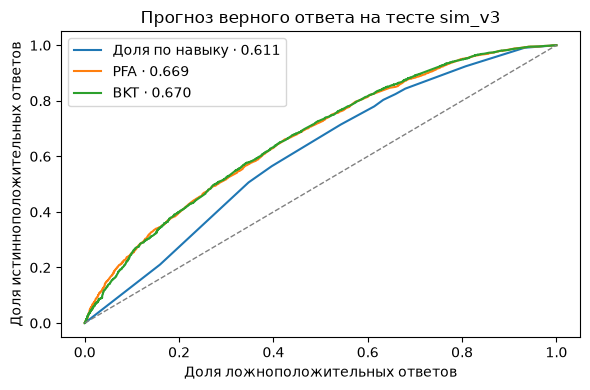

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import expit
from sklearn.metrics import auc, roc_curve

sys.dont_write_bytecode = True
if str(ml) not in sys.path:
    sys.path.insert(0, str(ml))
from compare_models import BKT_NAMES, learning_steps, predict_bkt

columns = ["child_id", "session_id", "task_id", "competency_id", "attempt_no",
           "occurred_at", "device_seq", "is_correct"]
events = pd.read_csv(events_path, usecols=columns)
steps = learning_steps(events.loc[events.child_id.isin(v1["test_child_ids"])])
parts = []
for skill, history in steps.groupby("competency_id"):
    model = v1["models"][skill]
    beta = model["PFA"]
    parts.append(history.assign(rate=model["rate"],
                                PFA=expit(beta["intercept"] + beta["success"] * history.past_correct
                                          + beta["failure"] * history.past_wrong),
                                BKT=predict_bkt(history, [model["BKT"][p] for p in BKT_NAMES])))
scores = pd.concat(parts)
n = len(scores)
y = np.repeat([1, 0], n)
weights = np.r_[scores.correct, scores.wrong]
fig, ax = plt.subplots(figsize=(6, 4))
for key in ("rate", "PFA", "BKT"):
    fpr, tpr, _ = roc_curve(y, np.tile(scores[key], 2), sample_weight=weights)
    area = auc(fpr, tpr)
    np.testing.assert_allclose(area, v1["test"][key]["AUC"], rtol=0, atol=1e-12)
    ax.plot(fpr, tpr, label=f"{labels[key]} · {area:.3f}")
ax.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
ax.set(xlabel="Доля ложноположительных ответов", ylabel="Доля истинноположительных ответов",
       title="Прогноз верного ответа на тесте sim_v3")
ax.legend()
fig.tight_layout()
plt.show()

## 4.1a и 4.1d. Чувствительность BKT к границам

В 4.1a сравниваются 48 комбинаций верхних границ. Выбор сделан по минимальному общему RMSE на валидации. При равенстве учитывался больший AUC. Каждая строка ниже задаёт потолки угадывания и ошибки, а столбцы — потолок обучения. Тестовые дети в выборе не участвовали.

In [6]:
def validation_grid(experiment: dict) -> pd.DataFrame:
    return pd.DataFrame([{**item["bounds"], **item["metrics"]} for item in experiment["validation_grid"]])


grid = validation_grid(v2)
display(grid.pivot(index=["guess_max", "slip_max"], columns="learn_max", values=["RMSE", "AUC"]).round(5))
print("Выбранные верхние границы 4.1a:", v2["selected_bounds"])

RMSE                        AUC                  
learn_max             0.500    0.900    0.999    0.500    0.900    0.999
guess_max slip_max                                                      
0.200     0.200     0.45700  0.45684  0.45686  0.67596  0.67649  0.67477
          0.300     0.45402  0.45376  0.45374  0.66122  0.66236  0.66247
          0.400     0.45403  0.45376  0.45374  0.66076  0.66181  0.66188
          0.499     0.45398  0.45371  0.45369  0.66081  0.66186  0.66192
0.300     0.200     0.45444  0.45428  0.45431  0.67458  0.67517  0.67421
          0.300     0.45302  0.45273  0.45271  0.66867  0.66976  0.66985
          0.400     0.45308  0.45278  0.45276  0.66827  0.66950  0.66956
          0.499     0.45303  0.45274  0.45271  0.66833  0.66956  0.66962
0.400     0.200     0.45253  0.45224  0.45226  0.67589  0.67644  0.67633
          0.300     0.45203  0.45163  0.45161  0.67444  0.67548  0.67556
          0.400     0.45204  0.45164  0.45162  0.67434  0.67538  0.67544
          0.499     0.45200  0.45160  0.45157  0.67443  0.67546  0.67553
0.499     0.200     0.45134  0.45102  0.45105  0.67708  0.67791  0.67782
          0.300     0.45121  0.45076  0.45073  0.67654  0.67795  0.67790
          0.400     0.45123  0.45077  0.45075  0.67647  0.67787  0.67781
          0.499     0.45118  0.45073  0.45070  0.67653  0.67794  0.67787

Выбранные верхние границы 4.1a: {'guess_max': 0.499, 'slip_max': 0.499, 'learn_max': 0.999}


В 4.1d потолки угадывания и ошибки фиксированы на 0,499. Среди потолков обучения, при которых валидационный RMSE превышает лучший не более чем на 0,0005, выбран наименьший. Такой критерий допускает небольшое ухудшение прогноза ради более низкого ограничения на переход к освоению.

In [7]:
caps = validation_grid(v4)[["learn_max", "RMSE", "AUC"]].copy()
caps["В пределах допуска"] = caps.RMSE <= v4["rmse_threshold"]
caps["Выбран"] = caps.learn_max == v4["selected_bounds"]["learn_max"]
display(caps.set_index("learn_max").round(6))
display(pd.DataFrame([{"Эксперимент": title, "Потолок p_learn": result["selected_bounds"]["learn_max"],
                       **result["test"]["metrics"]} for title, result in
                      [("4.1a, тест", v2), ("4.1d, тест", v4)]]).set_index("Эксперимент").round(6))

,RMSE,AUC,В пределах допуска,Выбран
learn_max,,,,
0.100,0.452511,0.670168,False,False
0.200,0.451483,0.675736,False,False
0.300,0.451271,0.676311,False,False
0.500,0.451181,0.676526,True,True
0.999,0.450704,0.677874,True,False


,Потолок p_learn,AUC,RMSE,answers,children
Эксперимент,,,,,
"4.1a, тест",0.999,0.669616,0.454925,9819,60
"4.1d, тест",0.500,0.668062,0.455322,9819,60


### Параметры итоговой BKT по навыкам

Для оценок на границе указана сторона ограничения. Достижение границы означает, что данные и заданная область поиска ограничивают идентификацию параметра. Сравнение 4.1a и 4.1d особенно существенно для BUD-4.

In [8]:
rows = []
for skill, fit in sorted(v4["test"]["by_skill"].items()):
    sides = {"lower": "нижняя", "upper": "верхняя"}
    edge = ", ".join(f"{p} ({sides[side]})" for p, side in fit["at_limit"].items())
    rows.append({"Навык": skill, **fit["parameters"], "На границе": edge or "—"})
display(pd.DataFrame(rows).set_index("Навык").round(5))

,p_init,p_learn,p_guess,p_slip,На границе
Навык,,,,,
BUD-1,0.30749,0.24400,0.49900,0.17940,p_guess (верхняя)
BUD-2,0.09585,0.38197,0.49627,0.18998,—
BUD-3,0.36580,0.12979,0.49900,0.22243,p_guess (верхняя)
BUD-4,0.00100,0.50000,0.43283,0.25034,"p_init (нижняя), p_learn (верхняя)"
PAY-1,0.12634,0.08179,0.31627,0.24701,—
PAY-2,0.07148,0.06925,0.34888,0.22001,—
PAY-3,0.25406,0.05491,0.49900,0.14894,p_guess (верхняя)
SAV-1,0.36930,0.03618,0.49900,0.20468,p_guess (верхняя)
SAV-2,0.50577,0.13425,0.44601,0.25839,—


## 4.1c. Согласие дневных оценок со скрытой способностью

Используется BKT v4, обученная на 240 детях. В симуляторе `true_mastery` — сигмоида непрерывной способности с поправкой на навыки-предпосылки. P(L) — вероятность скрытого состояния «освоено» в BKT. Одинаковый диапазон от 0 до 1 допускает сопоставление рангов, но смысл двух шкал различается.

Дневная пара соответствует ребёнку, навыку и дате по UTC+3. Состояние BKT после последнего шага сравнивается со снимком симулятора после занятий, перед ночным забыванием. До первой попытки используется начальное P(L), в дальнейшем дни без ответов получают последнюю оценку. Для корреляции Спирмена приведены 95%-ные интервалы по 2 000 кластерным выборкам детей (seed 2026).

In [9]:
scopes = v5["scopes"]
scope_labels = {"answer_days": "Дни с ответами по навыку", "all_days": "Все дни с переносом",
                "last_day": "Последний день, все пары", "last_day_with_history": "Последний день, с историей"}


def rho(cell: dict) -> str:
    stat = cell["spearman"]
    return with_ci(stat["rho"], stat["ci95"], digits=3)


display(pd.DataFrame([{"Наблюдения": title, "Число пар": scopes[key]["overall"]["spearman"]["n"],
                       "ρ [95% ДИ]": rho(scopes[key]["overall"])} for key, title in scope_labels.items()]
                    ).set_index("Наблюдения"))
print("Пар ребёнок–навык без единого первого ответа к последнему дню:", v5["last_day_without_answers"])

,Число пар,ρ [95% ДИ]
Наблюдения,,
Дни с ответами по навыку,4430,"0.553 [0.468, 0.621]"
Все дни с переносом,36960,"0.478 [0.404, 0.543]"
"Последний день, все пары",660,"0.579 [0.498, 0.646]"
"Последний день, с историей",649,"0.578 [0.501, 0.643]"


Пар ребёнок–навык без единого первого ответа к последнему дню: 11


### Корреляция по каждому навыку

На всех днях самые низкие оценки у SAV-2 (ρ ≈ 0,20) и BUD-2 (≈ 0,25). Далее идут BUD-3 и SAV-3 (обе ≈ 0,28). Ограничение выборки днями с ответами заметнее меняет оценку SAV-3 (≈ 0,47), чем BUD-3 (≈ 0,26). Это сравнение описывает ранжирование пар ребёнок–день внутри каждого навыка. По нему нельзя установить причину различий.

In [10]:
skills = sorted(v4["test"]["by_skill"])
display(pd.DataFrame([{"Навык": skill, **{scope_labels[key] + ", ρ [95% ДИ]": rho(scopes[key][skill])
                                          for key in ("answer_days", "all_days")}}
                      for skill in skills]).set_index("Навык"))

,"Дни с ответами по навыку, ρ [95% ДИ]","Все дни с переносом, ρ [95% ДИ]"
Навык,,
BUD-1,"0.621 [0.511, 0.716]","0.572 [0.447, 0.676]"
BUD-2,"0.387 [0.259, 0.516]","0.252 [0.097, 0.394]"
BUD-3,"0.264 [0.028, 0.481]","0.281 [0.075, 0.475]"
BUD-4,"0.496 [0.386, 0.611]","0.325 [0.175, 0.473]"
PAY-1,"0.754 [0.666, 0.818]","0.746 [0.678, 0.807]"
PAY-2,"0.747 [0.644, 0.820]","0.722 [0.635, 0.791]"
PAY-3,"0.683 [0.535, 0.796]","0.686 [0.574, 0.773]"
SAV-1,"0.560 [0.343, 0.706]","0.432 [0.251, 0.582]"
SAV-2,"0.306 [0.086, 0.494]","0.197 [0.006, 0.380]"


### Описательная таблица по корзинам P(L)

По всем дням приведены число наблюдений и средние значения двух шкал внутри каждого интервала P(L). Корзины включают нижнюю границу, последняя также включает единицу. Разности между средними не трактуются как ошибки измерения истинной вероятности.

In [11]:
bins = scopes["all_days"]["overall"]["descriptive_bins"]
display(pd.DataFrame([{"Корзина P(L)": f"[{r['low']:.1f}, {r['high']:.1f}" + ("]" if r['high'] == 1 else ")"),
                       "Пар": r["n"], "Средняя P(L)": r["mean_p"], "Среднее true_mastery": r["mean_true_mastery"]}
                      for r in bins]).set_index("Корзина P(L)").round(3))

,Пар,Средняя P(L),Среднее true_mastery
Корзина P(L),,,
"[0.0, 0.1)",1658,0.074,0.426
"[0.1, 0.2)",6955,0.149,0.420
"[0.2, 0.3)",2429,0.247,0.523
"[0.3, 0.4)",4204,0.348,0.513
"[0.4, 0.5)",2640,0.438,0.520
"[0.5, 0.6)",4548,0.533,0.531
"[0.6, 0.7)",2066,0.663,0.559
"[0.7, 0.8)",1815,0.746,0.600
"[0.8, 0.9)",2495,0.842,0.649


### Согласие порогов на последний день

Основные пороги способности симулятора — 0,5 и 0,8. Согласие — доля пар, в которых классификация по P(L) ≥ 0,95 совпадает с классификацией по порогу симулятора. AUC рассчитывается по непрерывной P(L). Сравниваются все пары и пары с хотя бы одним наблюдавшимся ответом.

In [12]:
def threshold_row(row: dict, sample: str) -> dict:
    return {"Выборка": sample, "Порог true_mastery": row["truth_threshold"],
            "Положительных пар": f"{row['tp'] + row['fn']} из {row['n']}",
            "Согласие [95% ДИ]": with_ci(row["agreement"], row["ci95"], digits=3),
            "AUC": round(row["auc"], 3)}


display(pd.DataFrame([threshold_row(r, scope_labels[key]) for key in ("last_day", "last_day_with_history")
                      for r in scopes[key]["overall"]["thresholds"] if r["truth_threshold"] in (0.5, 0.8)]
                    ).set_index(["Выборка", "Порог true_mastery"]))

Положительных пар  \
Выборка                    Порог true_mastery                     
Последний день, все пары   0.5                       456 из 660   
                           0.8                       161 из 660   
Последний день, с историей 0.5                       452 из 649   
                           0.8                       161 из 649   

                                                  Согласие [95% ДИ]    AUC  
Выборка                    Порог true_mastery                               
Последний день, все пары   0.5                 0.558 [0.518, 0.597]  0.745  
                           0.8                 0.774 [0.747, 0.802]  0.837  
Последний день, с историей 0.5                 0.556 [0.519, 0.596]  0.744  
                           0.8                 0.770 [0.744, 0.797]  0.834

**Дополнительный порог 0,95.** На последнем дне ему соответствуют только 6 положительных пар из 660. Для полноты приведена отдельная строка без интерпретации AUC.

In [13]:
rare = next(r for r in scopes["last_day"]["overall"]["thresholds"] if r["truth_threshold"] == 0.95)
display(pd.DataFrame([threshold_row(rare, "Последний день, все пары")]).set_index("Выборка"))

,Порог true_mastery,Положительных пар,Согласие [95% ДИ],AUC
Выборка,,,,
"Последний день, все пары",0.95,6 из 660,"0.679 [0.633, 0.723]",0.972


### Траектории по персонам

Для каждой персоны заранее выбран один тестовый ребёнок с наименьшим идентификатором. На графиках показаны дневные траектории двух оценок по навыкам. Это индивидуальные иллюстрации. Они не дают оценки эффекта персоны.

**Персона careless** · ребёнок `1780ce37-25fa-48fe-a24c-4e38b29ba9e9`

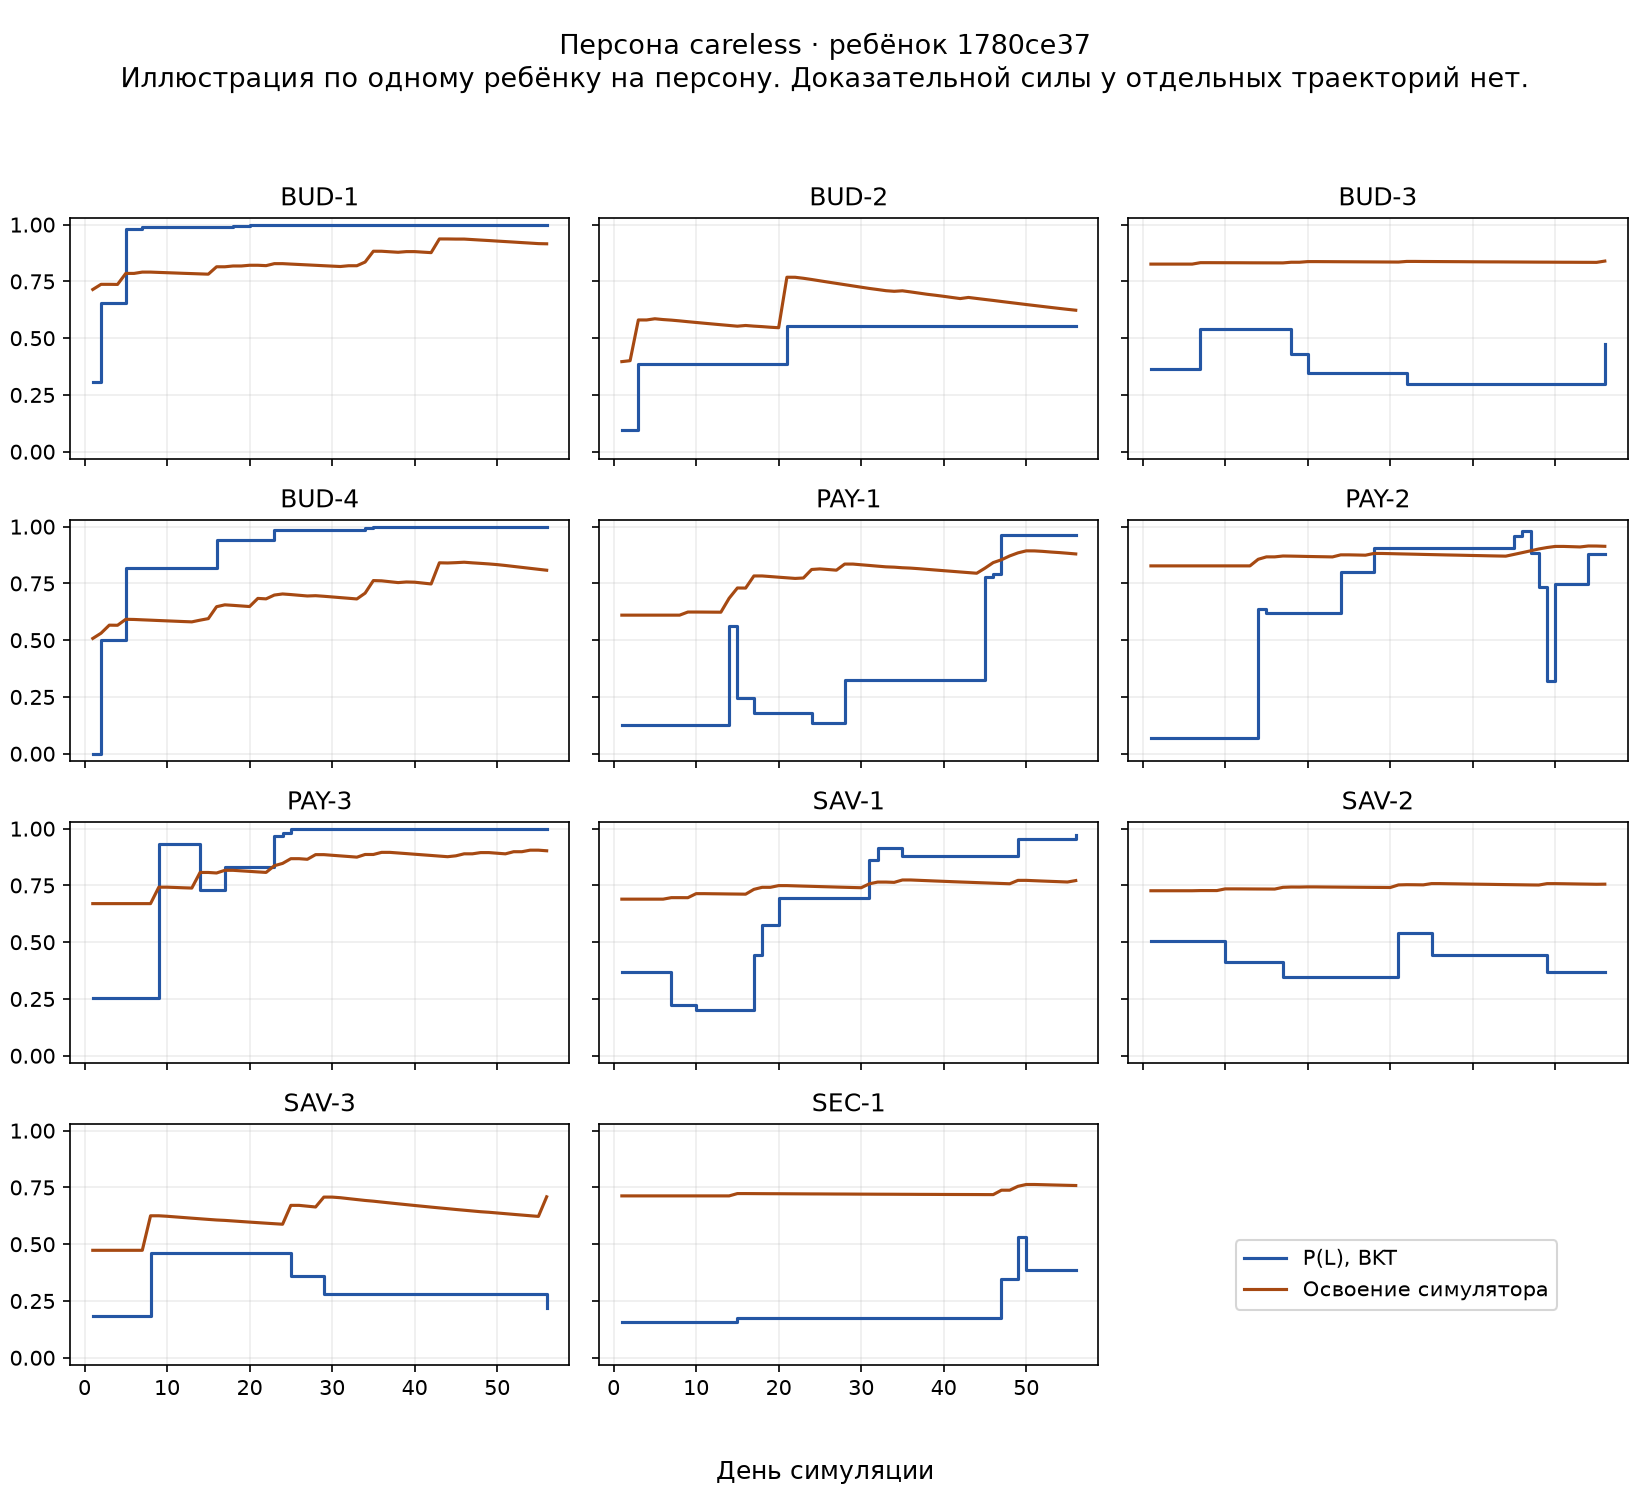

**Персона clicker** · ребёнок `3e21eaa9-5a8f-4dd0-9d58-b306ddf6d523`

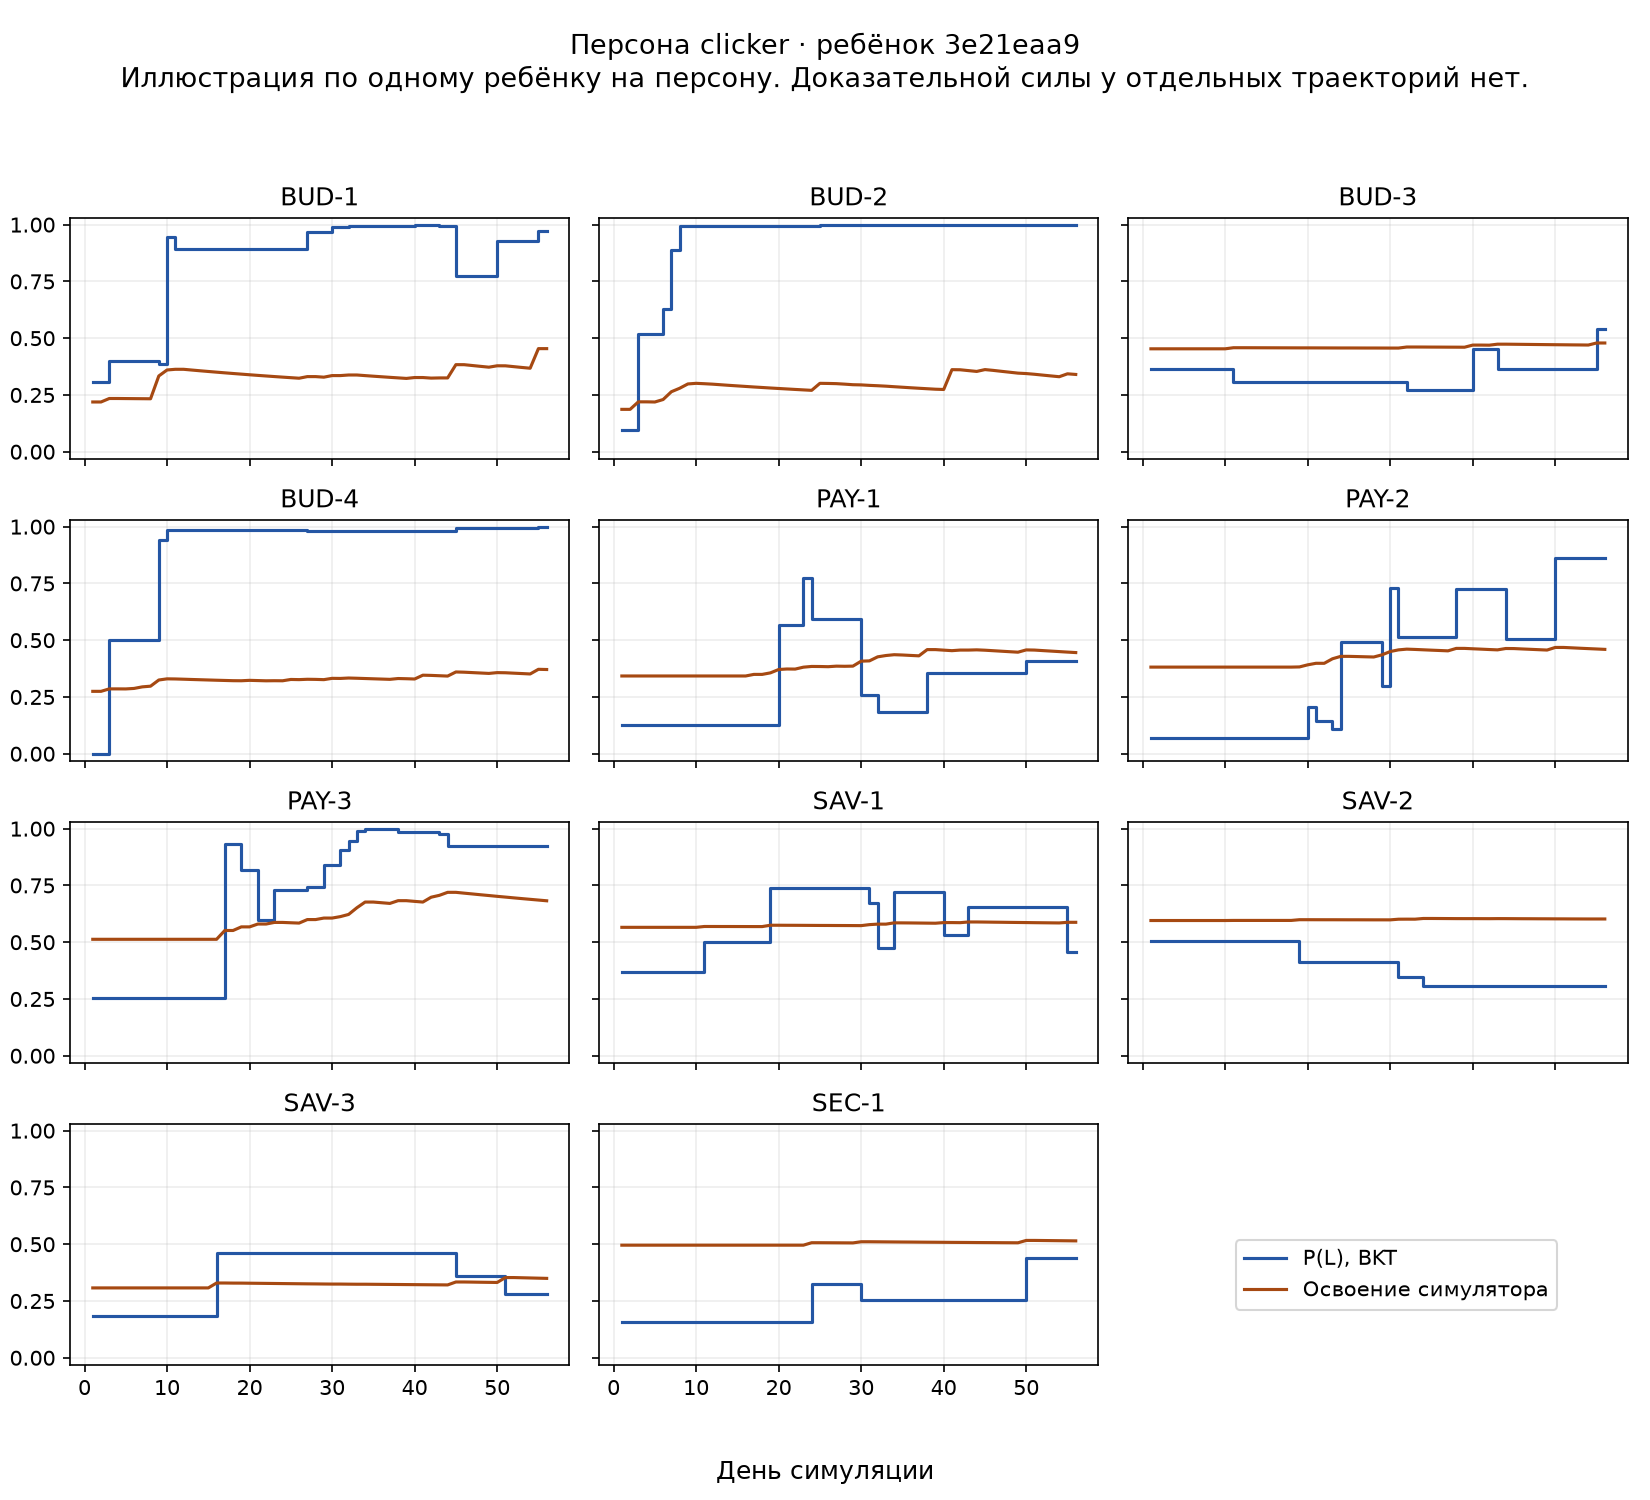

**Персона diligent** · ребёнок `023b5afb-b8a0-4f13-8eb5-60e1debf414a`

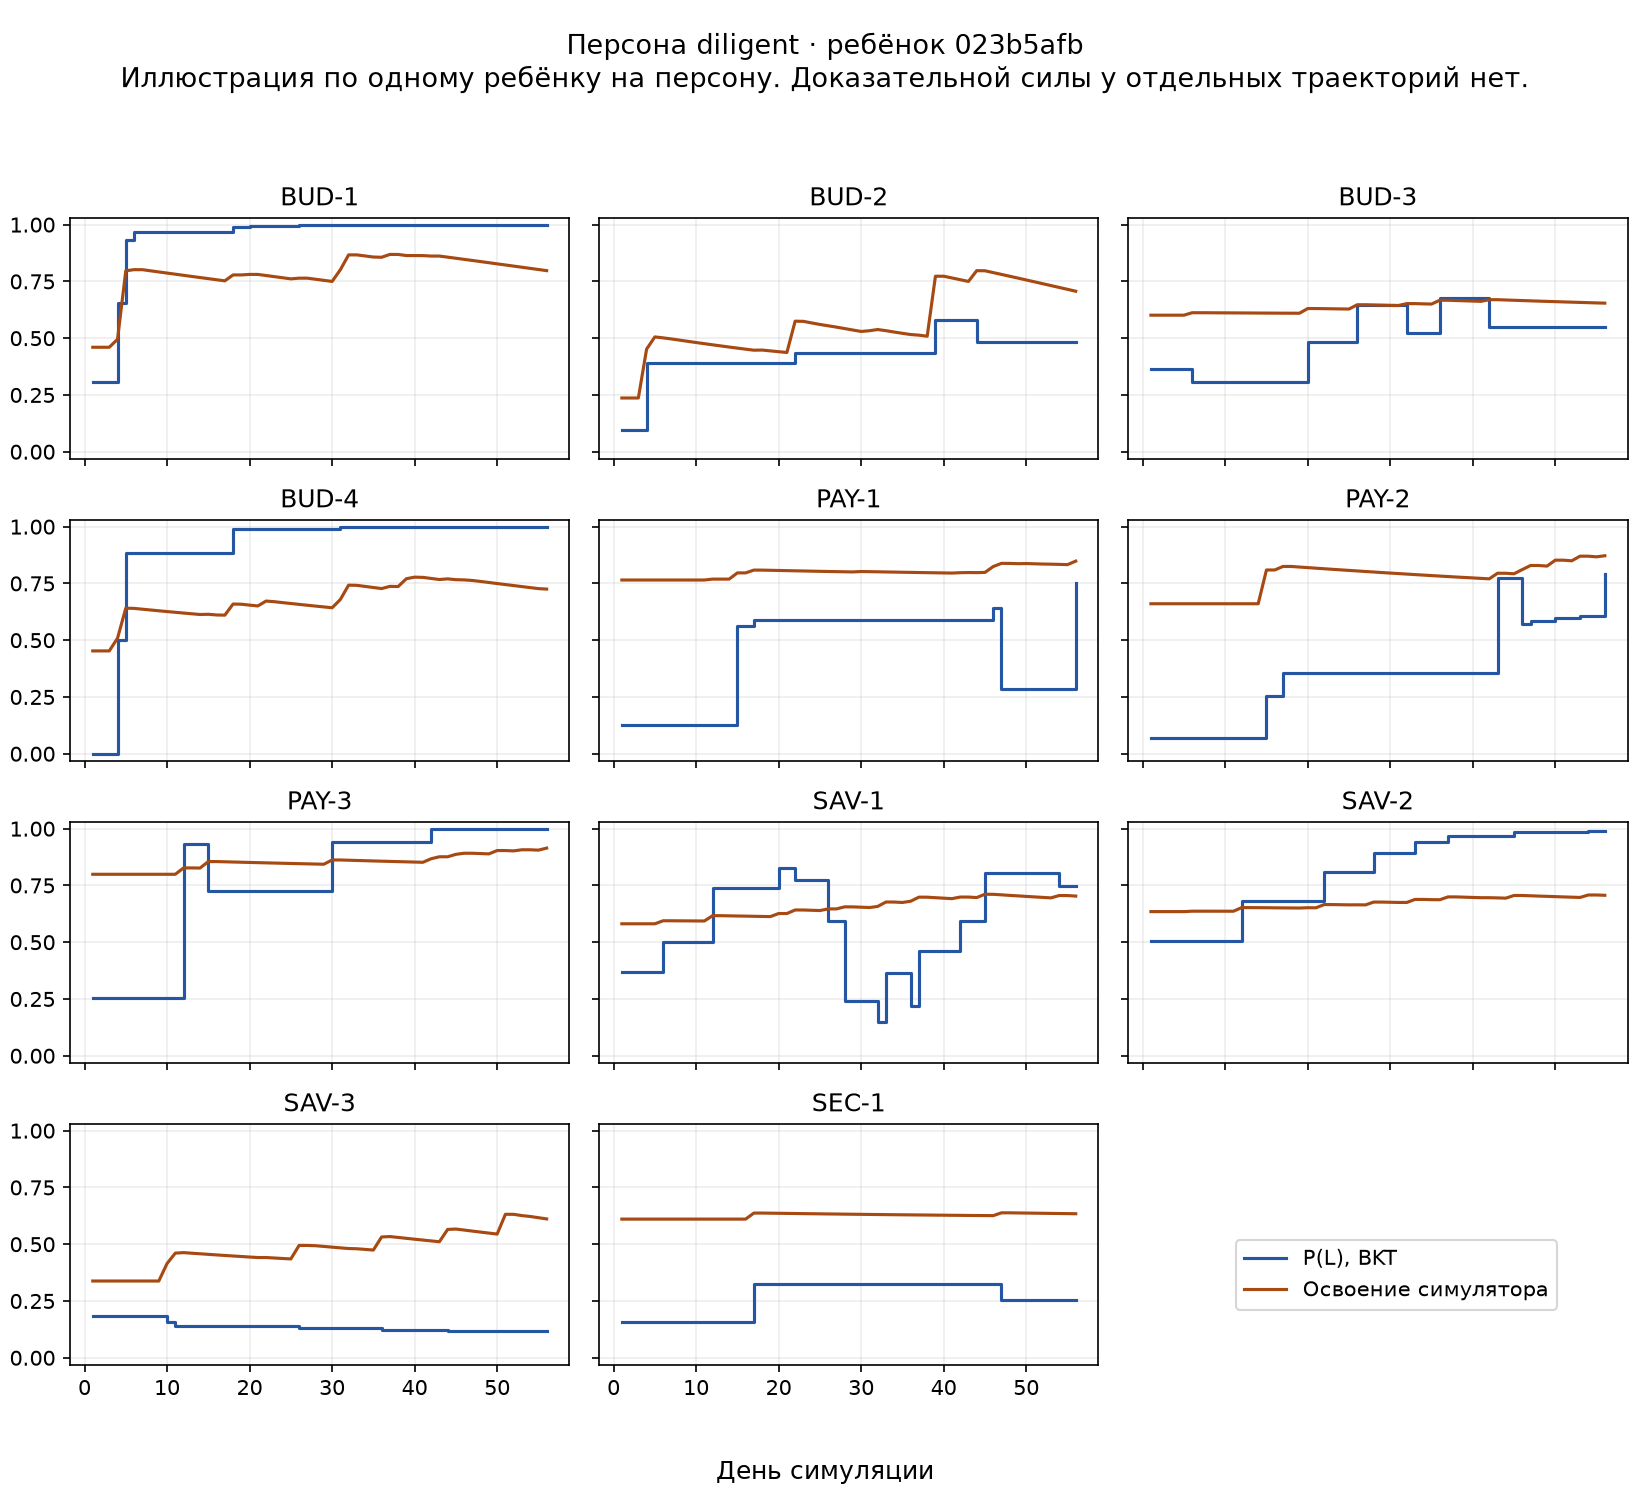

**Персона quick** · ребёнок `230abe2b-2cae-40b2-bb19-43441e4a2d42`

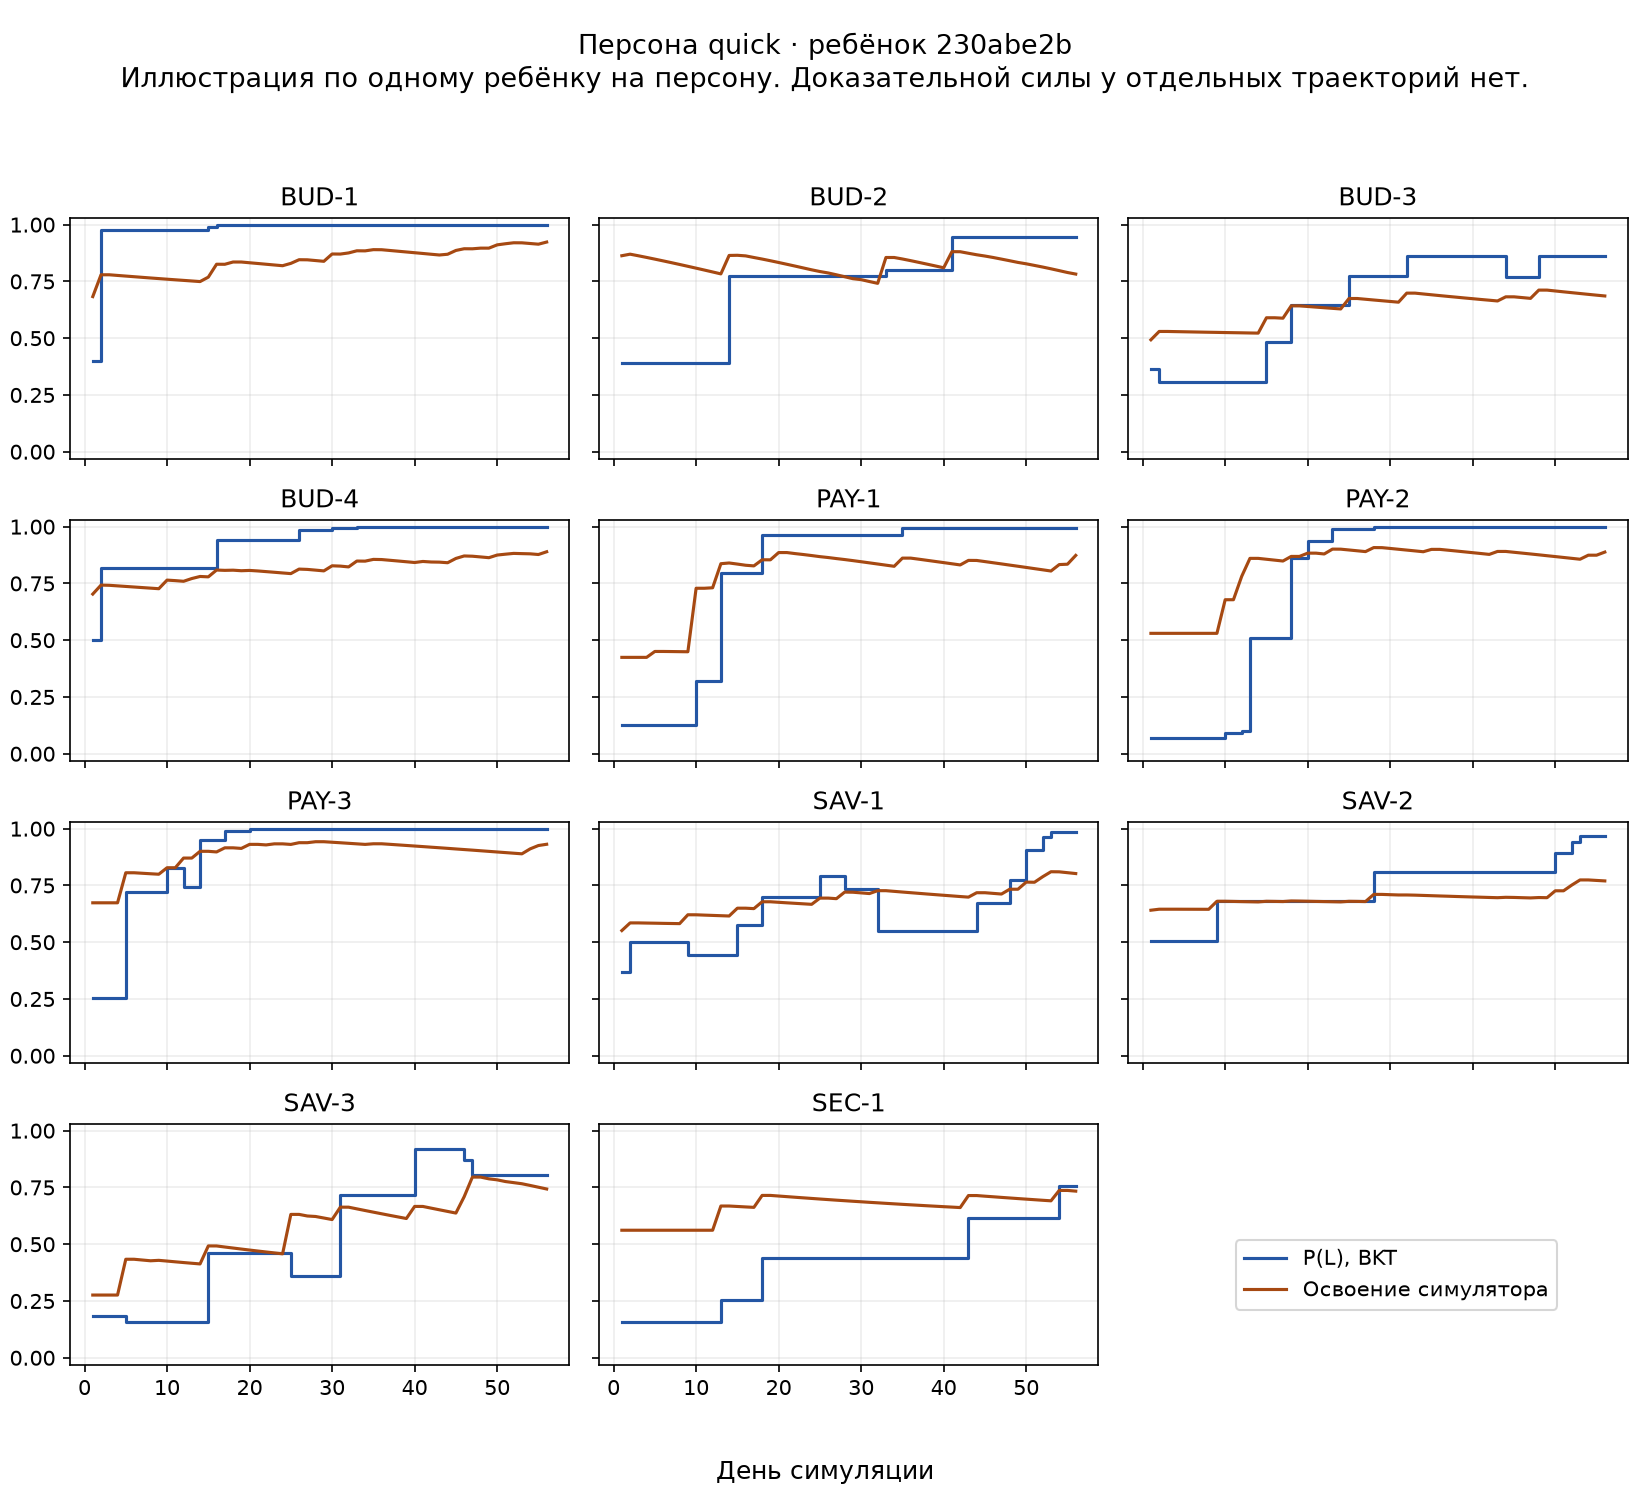

**Персона rare** · ребёнок `122edb27-13e8-4feb-8bab-01a6abb62c3e`

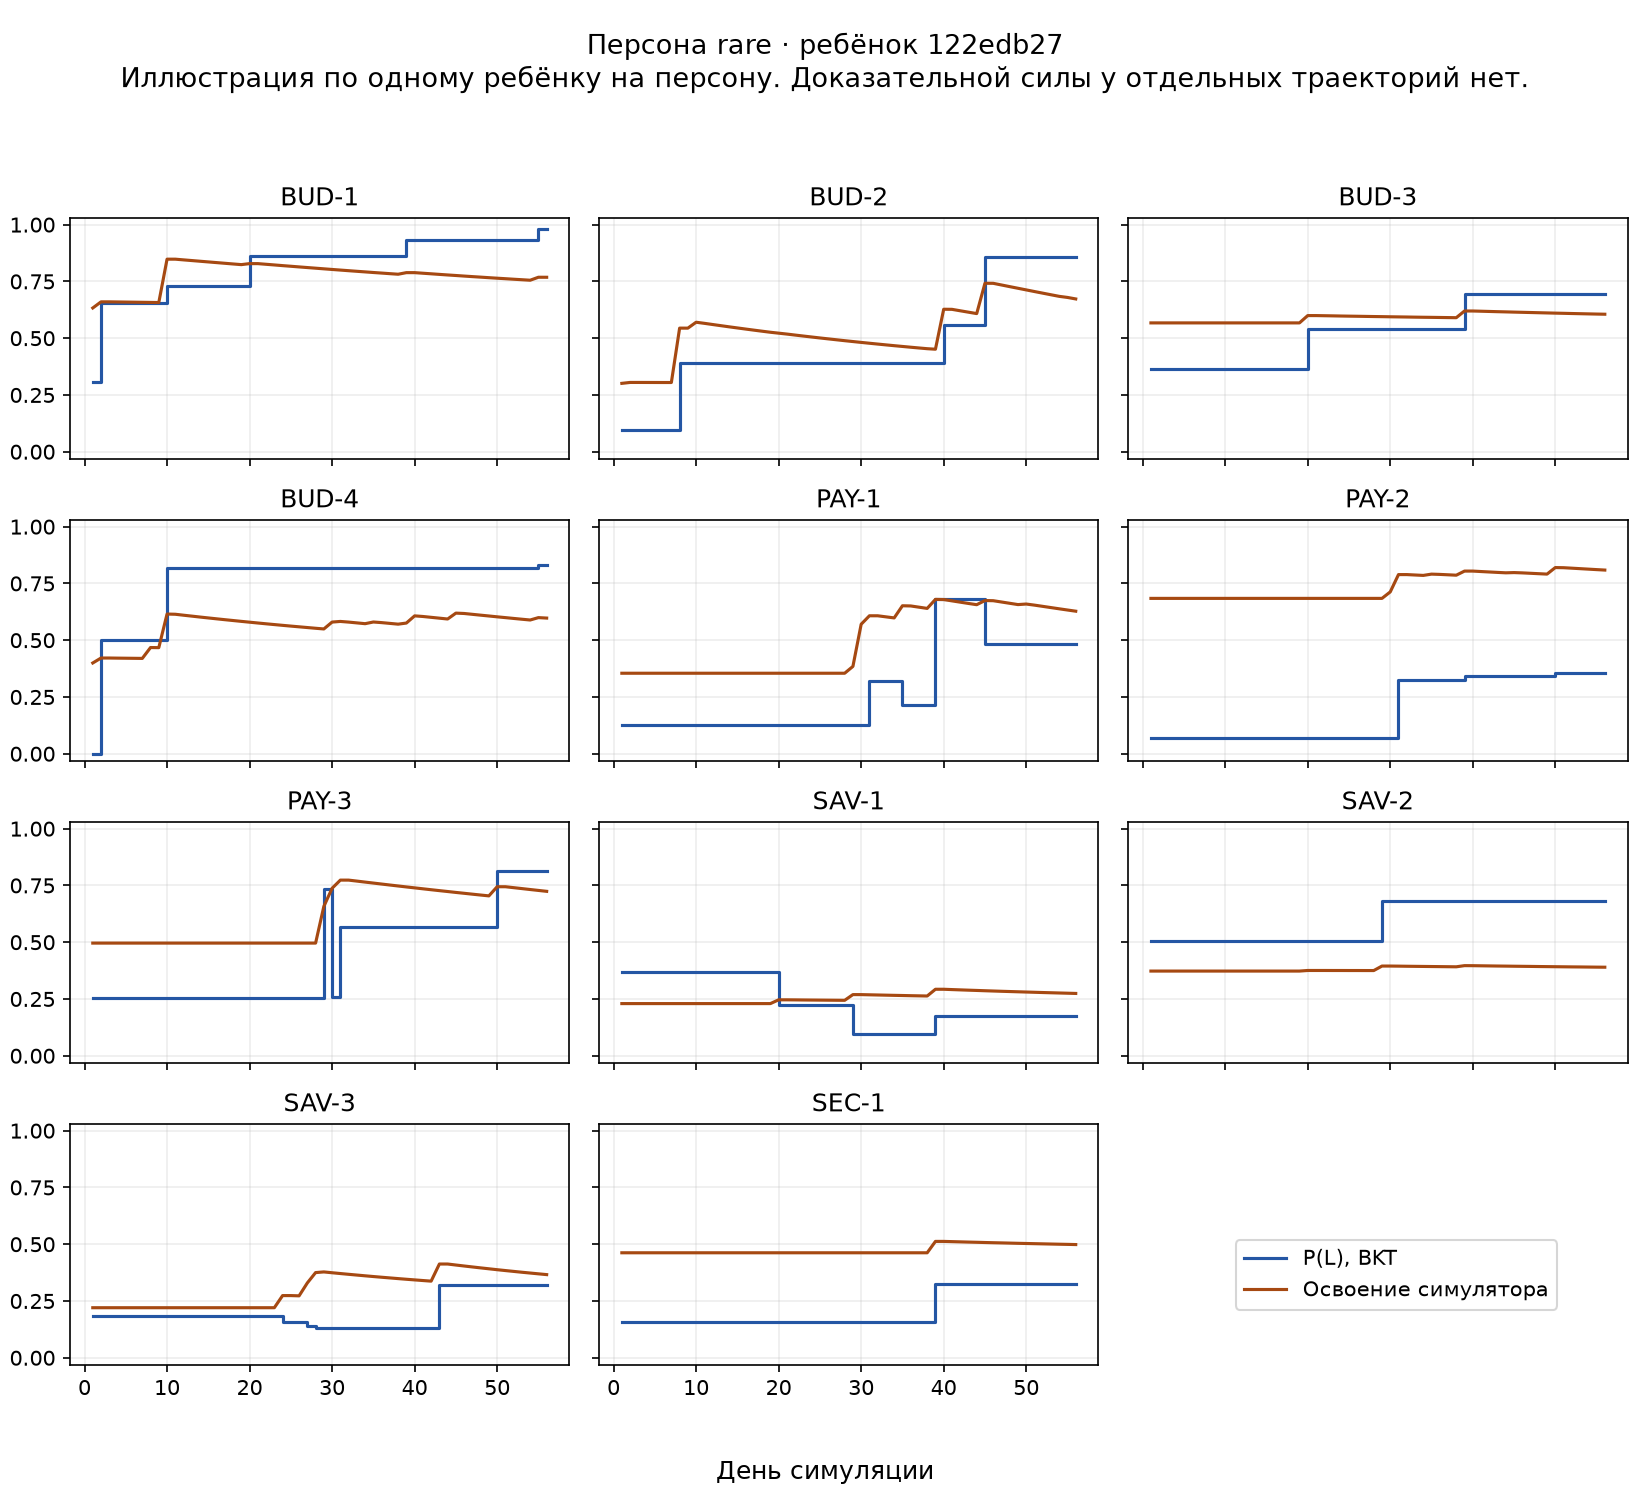

**Персона slow** · ребёнок `01022f75-4028-46b9-8fd9-a53c5bc1a3af`

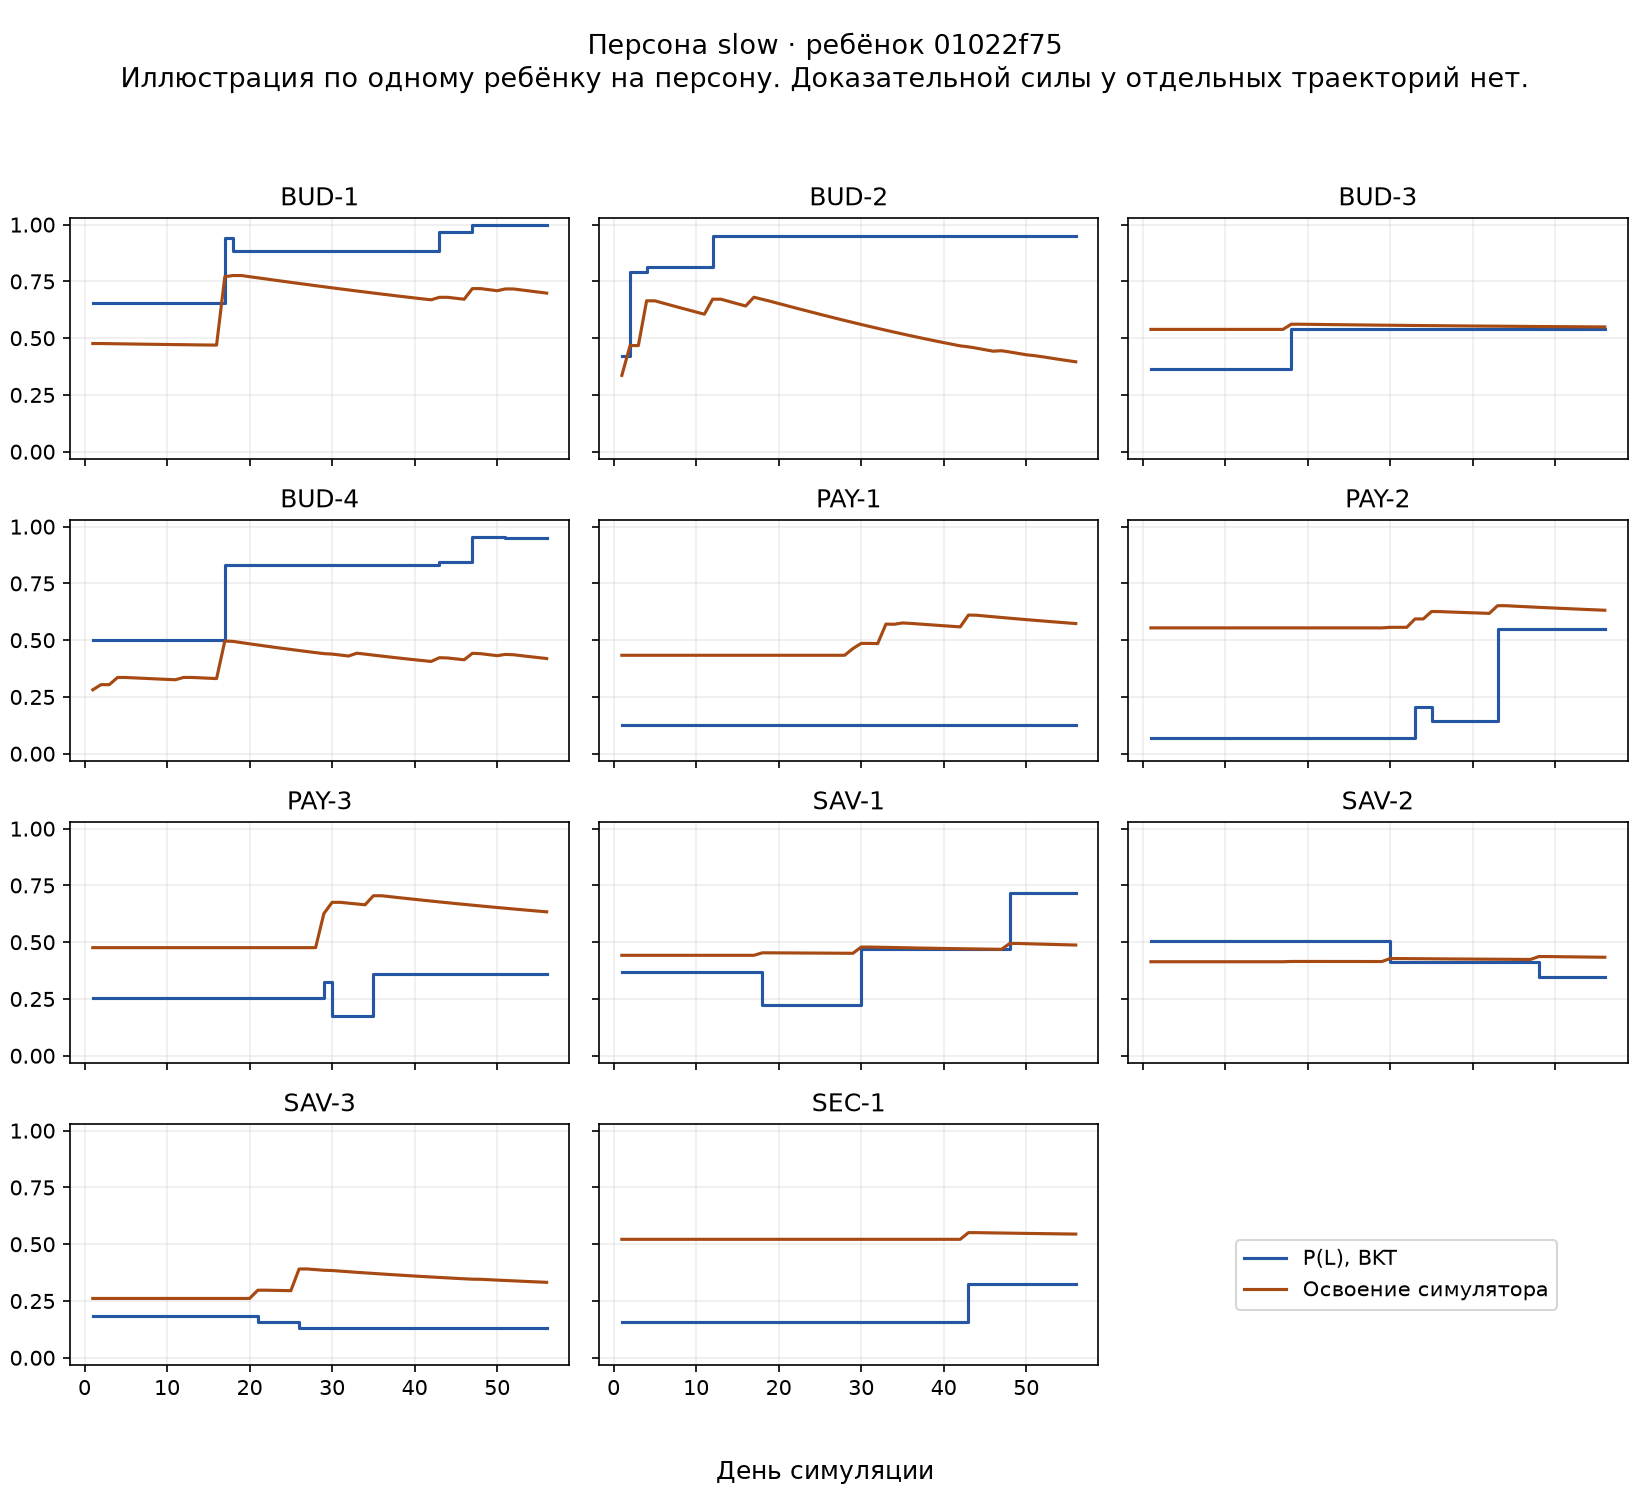

In [14]:
for item in v5["trajectories"]:
    display(Markdown(f"**Персона {item['persona']}** · ребёнок `{item['child_id']}`"))
    display(Image(filename=str(results / item["file"]), width=820))

## Ограничения

- Все эксперименты используют один набор `sim_v3` с seed 42. Повторов генерации с другими seed и проверки на данных реальных детей в этих результатах нет. Бутстреп характеризует вариацию по детям внутри этого набора.
- Сложность заданий заложена в симулятор. Диагностическая PFA с `task_id` может использовать устойчивые различия между конкретными заданиями. На реальных данных величина выигрыша может быть меньше.
- В симуляторе вероятность верного ответа включает угадывание и ошибку при высокой способности. Эта форма похожа на наблюдательную часть BKT, хотя способность в симуляторе непрерывна, зависит от предпосылок и подвержена забыванию.
- Несколько параметров BKT достигли границ. У BUD-4 потолок обучения изменился с 0,999 в 4.1a до 0,5 в 4.1d, и в обеих подгонках оценка достигла потолка. В v4 начальное освоение этого навыка также достигло нижней границы 0,001. Два задания BUD-4 различаются по сложности. По этим данным нельзя уверенно отделить эффект задания от перехода к освоению.
- У дневного `true_mastery` и P(L) различный смысл. Кроме того, в дни без ответов BKT сохраняет последнее состояние, а скрытая способность симулятора может меняться. Дневные корреляции и описательные корзины относятся к этому способу сопоставления.